# 03 — Análise fatorial

Spec 002, perguntas Q2.1 a Q2.4. A **análise fatorial (AF)** supõe que cada item é explicado por fatores comuns
mais um erro próprio: $x = \Lambda f + \varepsilon$, com $\mathrm{Cov}(x) = \Lambda\Phi\Lambda^\top + \Psi$.
Diferente da PCA (que resume a variância **total**), a AF modela só a variância **comum** — a parte que os
itens compartilham. Os números deste notebook são recalculados aqui e conferidos com `resultados/002/tabelas/`.

Desde 2026-11-27 os EUA (NHANES 2005-06) estão fora do trabalho; as hipóteses H2.2–H2.4, que comparavam
Brasil e EUA, foram retiradas. O exemplo principal é o PHQ-9 da PNS 2019.

In [1]:
import sys, pathlib
raiz = pathlib.Path.cwd()
while not (raiz / "analise").is_dir():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
from analise.comum import caminhos, multivariada as mv
from analise.comum.estatistica import le_csv
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
TAB = caminhos.RESULTADOS / "002" / "tabelas"; FIG = caminhos.RESULTADOS / "002" / "figuras"

pns = pd.read_parquet(caminhos.processado("pns2019"))
phq = [f"phq{i}" for i in range(1, 10)]
from analise.harmonizacao.recodes import PHQ_ROTULOS
Xb = pns[phq].dropna().to_numpy(float)
Rb = np.corrcoef(Xb, rowvar=False)
print("PHQ-9: PNS n =", len(Xb))

PHQ-9: PNS n = 88531


## 1. Os dados servem para AF? KMO, MSA, Bartlett e α

- **α de Cronbach** mede a **consistência interna**: se os itens "andam juntos" a ponto de a soma ser um bom
  resumo. $\alpha = \frac{k}{k-1}(1 - \sum s_j^2 / s_T^2)$; vai de 0 a 1. No índice de insônia do Vigitel,
  α = 0,84.
- **KMO** (Kaiser-Meyer-Olkin) mede se as correlações entre os itens são explicadas por algo **em comum** a todos,
  e não só por pares de itens: compara as correlações com as correlações **parciais** (pela inversa de $R$),
  $\mathrm{KMO} = \sum r_{ij}^2 / (\sum r_{ij}^2 + \sum q_{ij}^2)$. Vai de 0 a 1; perto de 1 = vale fazer AF;
  regra prática KMO ≥ 0,60 (*a verificar*). O **MSA** é o mesmo índice item a item. No Vigitel, KMO = 0,71.
- **Bartlett**: testa $H_0$: $R = I$ (itens não correlacionados).
  $\chi^2 = -(n-1-(2p+5)/6)\ln|R|$, gl $= p(p-1)/2$.

In [2]:
k, msa = mv.kmo(Rb); chi2, gl, pv = mv.bartlett(Rb, len(Xb))
print(f"PNS 2019, PHQ-9: KMO = {k:.3f}; MSA mín = {msa.min():.3f}; Bartlett χ² = {chi2:,.1f}, gl = {gl}, p = {pv:.2e}; α = {mv.alfa_cronbach(Xb):.3f}")
le_csv(TAB / "adequacao.csv")[["conjunto", "n", "p", "alfa", "kmo", "bartlett_chi2", "bartlett_gl", "k_paralela"]]

PNS 2019, PHQ-9: KMO = 0.903; MSA mín = 0.859; Bartlett χ² = 291,781.2, gl = 36, p = 0.00e+00; α = 0.856


,conjunto,n,p,alfa,kmo,bartlett_chi2,bartlett_gl,k_paralela
0,insonia3_vigitel,27048,3,0.835,0.707,33128.117,3,1
1,phq9_pns,88531,9,0.856,0.903,291781.230,36,1
2,sassv_xuzhou,2317,10,0.877,0.864,11199.528,45,2
3,doomscrolling_turquia,1216,15,0.947,0.956,12808.232,105,1
4,procrastinacao_turquia,1216,9,0.810,0.832,3631.359,36,2
5,ais_japao,381,8,0.897,0.891,1660.917,28,1
6,bps_japao,381,9,0.808,0.846,1457.742,36,2


Com n de milhares, o Bartlett rejeita $H_0$ sempre (p arredondado para 0): ele só confirma que há correlação a
modelar. O tamanho do efeito está no KMO e no α.

## 2. Extração por máxima verossimilhança (ML) e por eixos principais

- **ML**: escolhe as unicidades $\Psi$ que maximizam a verossimilhança normal; minimiza
  $-\sum_{j>k}(\ln\lambda_j - \lambda_j) - k + p$ sobre os autovalores de $\Psi^{-1/2}R\Psi^{-1/2}$.
- **Eixos principais**: troca a diagonal de $R$ pelas comunalidades $h^2$ e repete a decomposição até convergir.

**Comunalidade** $h_j^2 = \sum_k \lambda_{jk}^2$ = parte da variância do item explicada pelos fatores;
**unicidade** $= 1 - h_j^2$.

In [3]:
mlb = mv.af_ml(Rb, 1)
pab = mv.af_eixos_principais(Rb, 1)
pd.DataFrame({"ML": mlb["cargas"][:, 0], "eixos principais": pab["cargas"][:, 0], "h² (ML)": mlb["comunalidades"],
              "unicidade": 1 - mlb["comunalidades"]}, index=PHQ_ROTULOS).round(3)

,ML,eixos principais,h² (ML),unicidade
interesse,0.754,0.753,0.568,0.432
deprimido,0.773,0.773,0.597,0.403
sono,0.543,0.545,0.295,0.705
cansaço,0.675,0.677,0.456,0.544
apetite,0.571,0.575,0.327,0.673
fracasso,0.691,0.686,0.478,0.522
concentração,0.687,0.686,0.472,0.528
psicomotor,0.627,0.631,0.393,0.607
autolesão,0.464,0.459,0.215,0.785


## 3. Onde carrega o item de sono do PHQ-9?

Com 1 fator (a solução retida pela análise paralela), o item de sono carrega no único fator. Como a literatura
costuma separar no PHQ-9 um fator **somático** e um **afetivo**, rodamos também uma solução **exploratória** de 2
fatores com rotação **oblimin** (oblíqua: os fatores podem se correlacionar; Φ é a correlação entre eles).

In [4]:
L2 = mv.af_ml(Rb, 2)["cargas"]; P, Phi, _ = mv.oblimin(L2)
print(f"PNS: Φ(F1,F2) = {Phi[0,1]:.3f}")
display(pd.DataFrame(P, index=PHQ_ROTULOS, columns=["F1", "F2"]).round(2))
le_csv(TAB / "phq9_item_sono.csv")

PNS: Φ(F1,F2) = 0.692


,F1,F2
interesse,0.74,0.05
deprimido,0.32,0.54
sono,0.60,-0.04
cansaço,0.83,-0.13
apetite,0.50,0.10
fracasso,-0.01,0.86
concentração,0.63,0.08
psicomotor,0.53,0.12
autolesão,0.00,0.54


,conjunto,solucao,k,fator_do_sono,carga_sono,fator_do_cansaco,fator_do_humor
0,phq9_pns,ML 1 fator(es) nenhuma,1,F1,0.543,F1,F1
1,phq9_pns,"ML 2 fator(es) oblimin (exploratória, 2 fatores)",2,F1,0.597,F1,F2


Na solução exploratória de 2 fatores, o item de sono fica no mesmo fator que **cansaço** (o fator somático), não
no do humor deprimido.

## 4. Conjuntos com 2 fatores: varimax × oblimin

Para SAS-SV (China), procrastinação do sono (Turquia) e BPS (Japão) a análise paralela retém 2 fatores.
**Varimax** força fatores não correlacionados (ortogonal); **oblimin** permite correlação.

,conjunto,metodo,k,fator_a,fator_b,phi
0,phq9_pns,ml (exploratória),2,F1,F2,0.692
1,sassv_xuzhou,ml,2,F1,F2,0.607
2,sassv_xuzhou,eixos principais,2,F1,F2,0.612
3,procrastinacao_turquia,ml,2,F1,F2,0.383
4,procrastinacao_turquia,eixos principais,2,F1,F2,0.377
5,bps_japao,ml,2,F1,F2,0.188
6,bps_japao,eixos principais,2,F1,F2,0.189


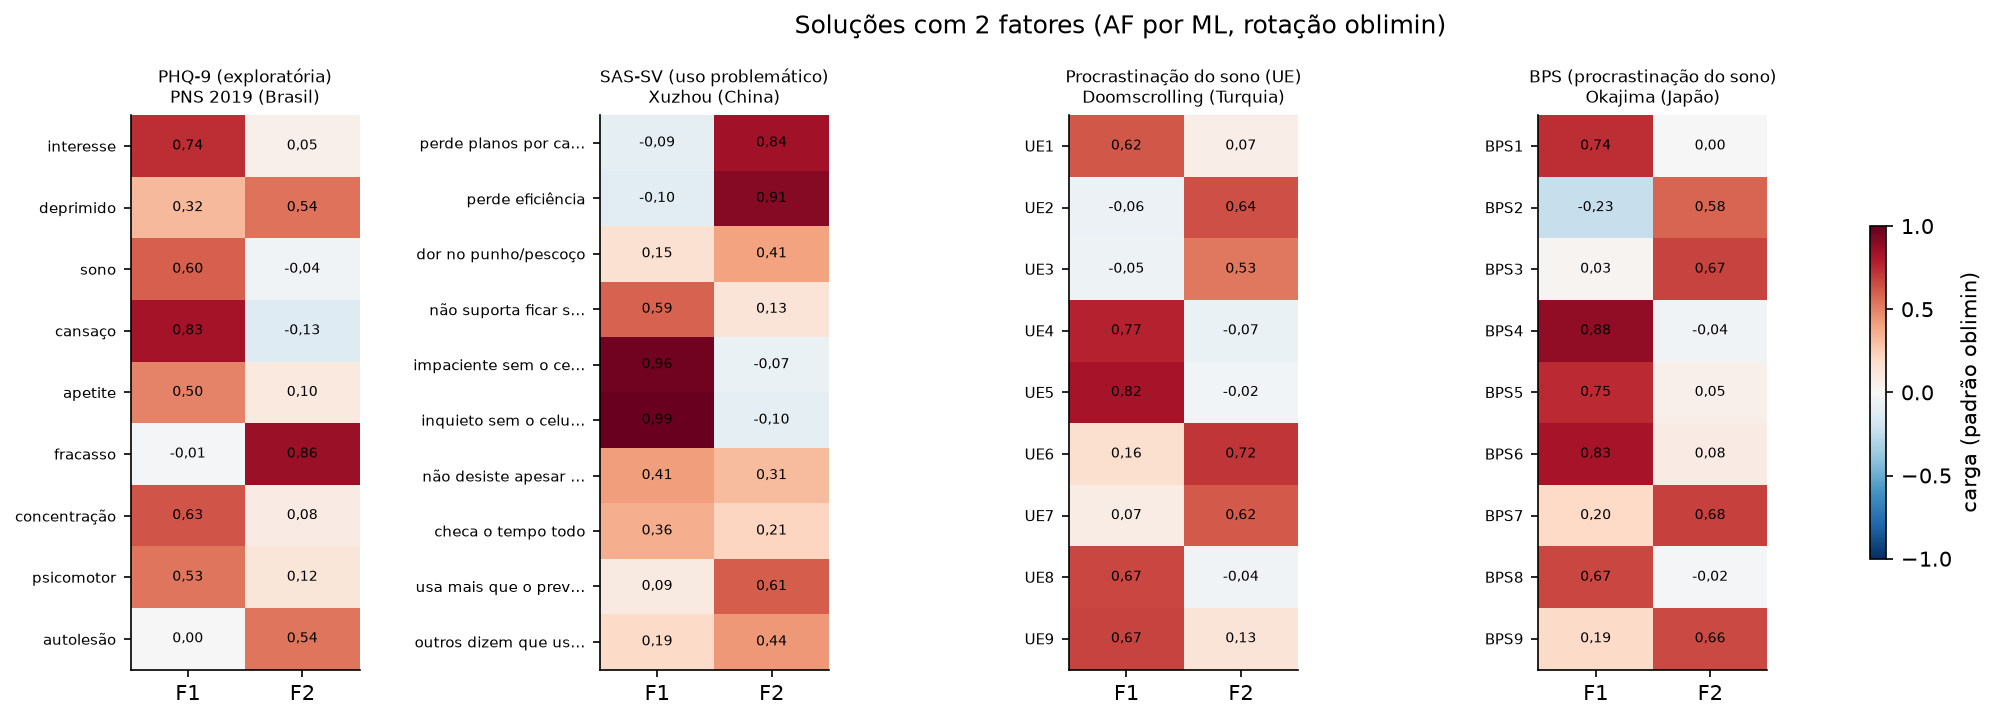

In [5]:
cg = le_csv(TAB / "af_cargas.csv"); phi = le_csv(TAB / "af_phi.csv")
display(phi)
display(Image(filename=str(FIG / "cargas_multifator.png")))

**Leitura.**
- **BPS (Japão)**: o 2º fator reúne exatamente os itens de redação invertida (BPS2R, BPS3R, BPS7R, BPS9R) e se
  correlaciona pouco com o 1º (Φ ≈ 0,19). É o padrão de um **fator de método** (efeito da redação), não
  necessariamente de dois construtos.
- **SAS-SV (China)**: um fator de "abstinência" (impaciente/inquieto/não suporta ficar sem o celular) e outro de
  "perturbação da rotina" (perde planos, perde eficiência, usa mais que o previsto), com Φ ≈ 0,61: dimensões
  distintas, mas bem correlacionadas.
- **Procrastinação (Turquia)**: dois blocos de itens (UE2, 3, 6, 7 × os demais), Φ ≈ 0,38. Sem codebook, não dá
  para afirmar se o 2º bloco é de itens invertidos.

## 5. Escores: PCA × AF × soma (H2.6)

Escore fatorial pelo método de regressão (Thurstone): $\hat F = Z\,R^{-1}\Lambda\Phi$.

In [6]:
Z = mv.padroniza(Xb)
f_af = mv.escores_regressao(Z, Rb, mlb["cargas"])[:, 0]
pc = mv.pca_svd(Xb)
pc1 = pc["escores"][:, 0]
print("PNS PHQ-9: r(PC1, AF) =", round(abs(np.corrcoef(pc1, f_af)[0, 1]), 4), " r(PC1, soma) =", round(abs(np.corrcoef(pc1, Xb.sum(axis=1))[0, 1]), 4))
le_csv(TAB / "escores_correlacao.csv")

PNS PHQ-9: r(PC1, AF) = 0.9967  r(PC1, soma) = 0.9953


,conjunto,n,r_pc1_af,r_pc1_soma,r_af_soma
0,insonia3_vigitel,27048,0.988,1.000,0.985
1,phq9_pns,88531,0.997,0.995,0.990
2,sassv_xuzhou,2317,0.953,0.999,0.944
3,doomscrolling_turquia,1216,0.999,0.999,0.997
4,procrastinacao_turquia,1216,0.978,0.992,0.945
5,ais_japao,381,0.995,0.999,0.992
6,bps_japao,381,0.971,0.968,0.891


## 6. Robustez: correlação policórica e correlação ponderada

Os itens são ordinais (0–3 ou 0–4). A correlação de Pearson entre categorias subestima a associação entre os
traços contínuos que estão por trás. A **policórica** (Olsson, 1979, doi:10.1007/BF02296207) estima essa
correlação supondo uma normal bivariada latente cortada em limiares: os limiares vêm das proporções marginais e
$\rho$ maximiza a verossimilhança da tabela cruzada. A **ponderada** usa o peso amostral do inquérito. O
coeficiente de Tucker aqui compara as cargas de cada solução com as da solução de Pearson **na mesma base**.

In [7]:
vg = pd.read_parquet(caminhos.processado("vigitel2024"))
Xi = vg[["sintoma_1", "sintoma_2", "sintoma_3"]].dropna().to_numpy(int)
Rp = mv.policorica(Xi)
print("Vigitel 2024, 3 sintomas — Pearson:\n", np.corrcoef(Xi, rowvar=False).round(3), "\npolicórica:\n", Rp.round(3))
le_csv(TAB / "robustez.csv")[["conjunto", "correlacao", "lambda1", "var1", "k_kaiser", "tucker_vs_pearson"]]

Vigitel 2024, 3 sintomas — Pearson:
 [[1.    0.626 0.561]
 [0.626 1.    0.701]
 [0.561 0.701 1.   ]] 
policórica:
 [[1.    0.69  0.621]
 [0.69  1.    0.76 ]
 [0.621 0.76  1.   ]]


,conjunto,correlacao,lambda1,var1,k_kaiser,tucker_vs_pearson
0,insonia3_vigitel,Pearson,2.261,0.754,1,1.000
1,insonia3_vigitel,policórica,2.382,0.794,1,1.000
2,insonia3_vigitel,ponderada pelo peso amostral,2.234,0.745,1,1.000
3,phq9_pns,Pearson,4.349,0.483,1,1.000
4,phq9_pns,policórica,5.828,0.648,1,0.996
5,phq9_pns,ponderada pelo peso amostral,4.390,0.488,1,1.000
6,sassv_xuzhou,Pearson,4.784,0.478,2,1.000
7,doomscrolling_turquia,Pearson,8.750,0.583,1,1.000
8,procrastinacao_turquia,Pearson,3.669,0.408,2,1.000
9,ais_japao,Pearson,4.690,0.586,1,1.000


A policórica aumenta as correlações e o 1º autovalor, como esperado, mas as cargas mantêm o mesmo padrão, e a
ponderação pelo peso amostral quase não muda nada (coluna `tucker_vs_pearson`).

## 7. Decisão sobre as hipóteses

In [8]:
le_csv(TAB / 'hipoteses.csv')

,hipotese,conjunto,criterio,valor,decisao
0,H2.1,insonia3_vigitel,"análise paralela retém 1 e cargas ≥ 0,50",retém 1; menor carga 0.708; λ1 = 2.261 (75.4%),critério atendido: 1 dimensão
1,H2.2,—,cargas do fator de insônia equivalentes entre ...,—,retirada em 2026-11-27 (EUA fora do trabalho)
2,H2.3,—,PHQ-9 com a mesma estrutura na PNS e no NHANES...,—,retirada em 2026-11-27 (EUA fora do trabalho)
3,H2.4,—,item de sono do PHQ-9 no mesmo fator nos dois ...,"descritivo, só PNS: na solução retida de 1 fat...",retirada em 2026-11-27 (EUA fora do trabalho)
4,H2.5,sassv_xuzhou,análise paralela retém 1,retém 2 (Kaiser 2); λ1 = 4.784 (47.8%),critério não atendido: 2 dimensões
5,H2.5,doomscrolling_turquia,análise paralela retém 1,retém 1 (Kaiser 1); λ1 = 8.750 (58.3%),critério atendido: unidimensional
6,H2.5,procrastinacao_turquia,análise paralela retém 1,retém 2 (Kaiser 2); λ1 = 3.669 (40.8%),critério não atendido: 2 dimensões
7,H2.5,ais_japao,análise paralela retém 1,retém 1 (Kaiser 1); λ1 = 4.690 (58.6%),critério atendido: unidimensional
8,H2.5,bps_japao,análise paralela retém 1,retém 2 (Kaiser 2); λ1 = 3.822 (42.5%),critério não atendido: 2 dimensões
9,H2.6,insonia3_vigitel,"r(PC1, escore fatorial) ≥ 0,95",r = 0.9882,critério atendido


## Conclusão

- **H2.1**: as 3 perguntas de insônia do Vigitel 2024 formam 1 fator (α = 0,84, KMO = 0,71,
  75% da variância no 1º componente). A soma delas é o índice de insônia.
- **H2.2–H2.4**: retiradas em 2026-11-27, com a saída dos EUA do trabalho. Fica o descritivo da PNS: o PHQ-9 tem
  1 fator, e o item de sono acompanha o cansaço quando se força a solução de 2 fatores.
- **H2.5**: doomscrolling e AIS são unidimensionais; SAS-SV, procrastinação (Turquia) e BPS têm 2 dimensões —
  no BPS, compatível com efeito dos itens invertidos.
- **H2.6**: escore da PCA e escore fatorial ordenam as pessoas quase igual (r ≥ 0,95 em todos os conjuntos).
- Consequência para as próximas specs: os índices por soma simples (insônia 0–12, PHQ-9 0–27, escores totais
  das escalas) são resumos adequados dos construtos, com a ressalva das escalas bidimensionais.